In [3]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("data")
manifest = json.loads((DATA / "manifest.json").read_text())
SESSIONS = manifest["sessions"]                          # ['s01', ..., 's24']
SYMBOLS = [s["symbol"] for s in manifest["symbols"]]     # ['HPPO', 'BNKY', 'CRRT', 'BRRY']
BATCHES_PER_MIN = 60_000 // manifest["batch_ms"]         # 120


In [4]:
def load_tops(name):
    """Top of book for one session, plus mid, spread and microprice (cents)."""
    df = pd.read_csv(DATA / f"{name}.top.csv")   # blank cell -> NaN: an empty side, never zero
    df["session"] = name
    df["mid"] = (df["bid_px"] + df["ask_px"]) / 2
    df["spread"] = df["ask_px"] - df["bid_px"]
    df["microprice"] = (df["bid_px"] * df["ask_qty"] + df["ask_px"] * df["bid_qty"]) / (df["bid_qty"] + df["ask_qty"])
    df["mid_ffill"] = df.groupby("symbol")["mid"].ffill()   # one-sided book: keep the last mid
    return df

def load_trades(name):
    """Every execution, with signed qty: + buyer-initiated, - seller-initiated."""
    df = pd.read_csv(DATA / f"{name}.trades.csv")
    df["session"] = name
    df["signed_qty"] = df["qty"].where(df["aggressor"] == "BUY", -df["qty"])
    return df

tops = pd.concat([load_tops(n) for n in SESSIONS], ignore_index=True)
trades = pd.concat([load_trades(n) for n in SESSIONS], ignore_index=True)
tops["minute"] = tops["batch"] / BATCHES_PER_MIN
trades["minute"] = trades["batch"] / BATCHES_PER_MIN

print(f"tops {len(tops):,} rows, trades {len(trades):,} rows")
print(tops.groupby("session").size().unique(), "rows per session")
print(tops.assign(one_sided=tops["mid"].isna()).groupby("symbol")["one_sided"].mean())


tops 518,400 rows, trades 1,271,552 rows
[21600] rows per session
symbol
BNKY    0.000000
BRRY    0.008819
CRRT    0.002006
HPPO    0.000648
Name: one_sided, dtype: float64


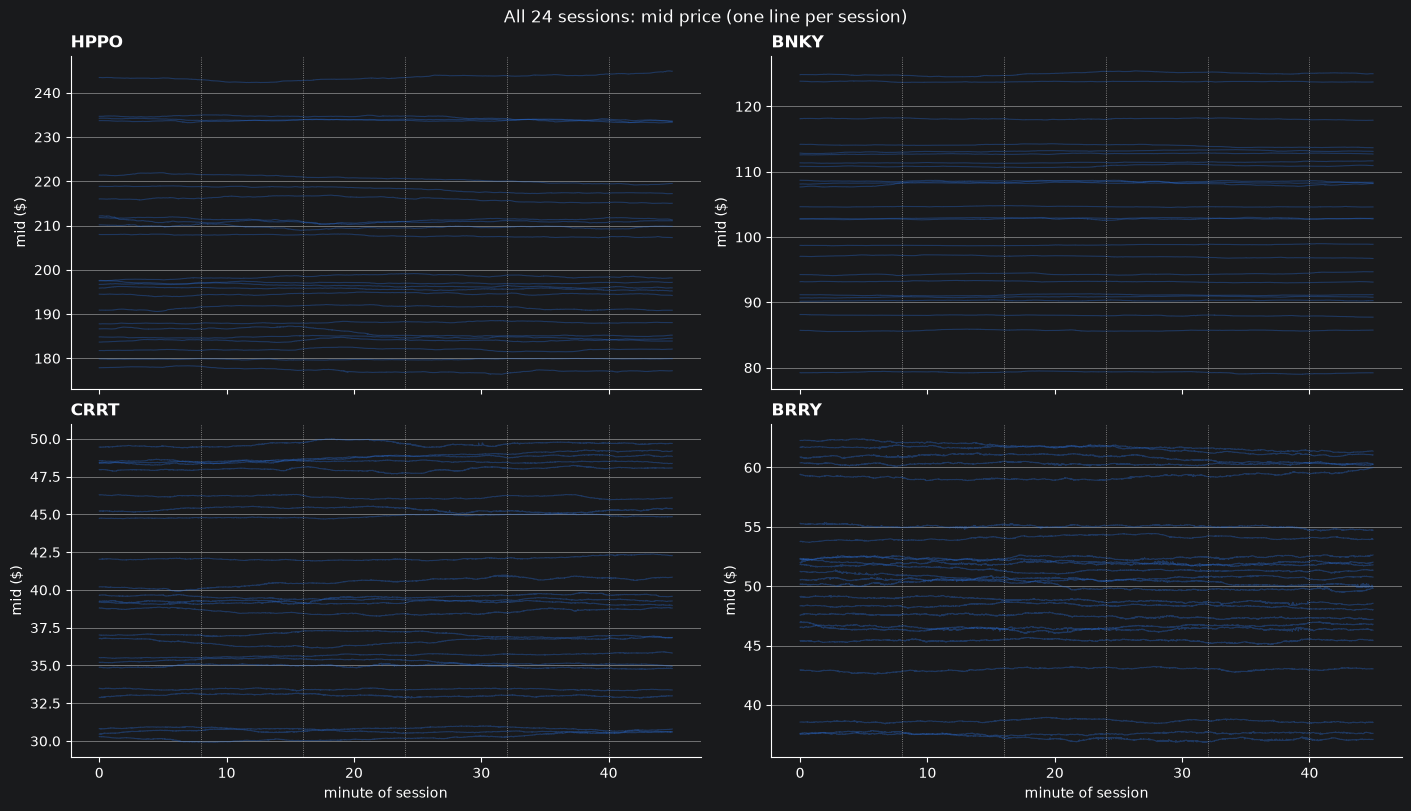

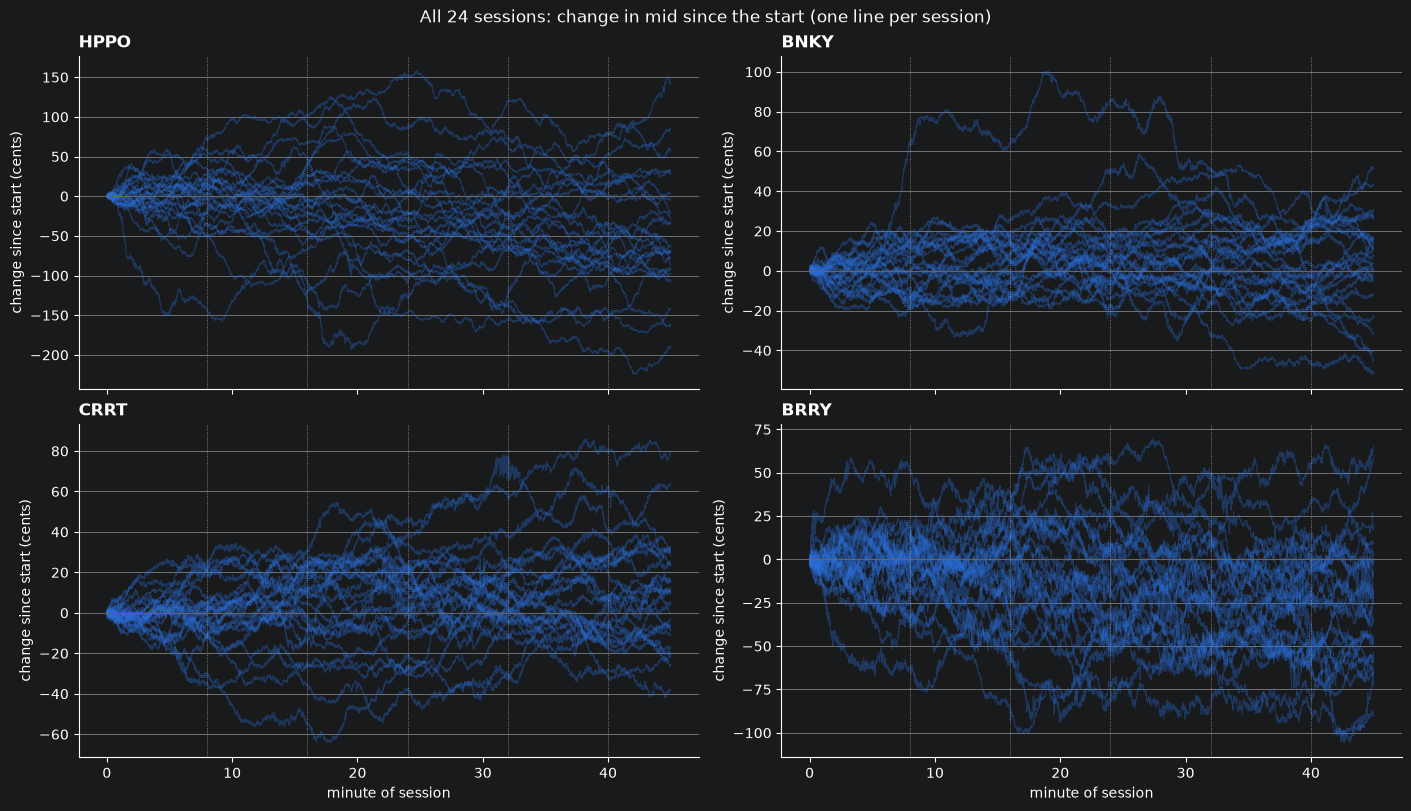

In [5]:
def plot_sessions(tops, relative=False):
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, layout="constrained")
    for ax, symbol in zip(axes.flat, SYMBOLS):
        sym = tops[tops["symbol"] == symbol]
        for _, s in sym.groupby("session"):
            y = s["mid_ffill"] - s["mid_ffill"].iloc[0] if relative else s["mid_ffill"] / 100
            ax.plot(s["minute"], y, color="#2a6fdb", linewidth=0.8, alpha=0.35)
        for day_end in range(8, 41, 8):
            ax.axvline(day_end, color="#999999", linewidth=0.6, linestyle=":")
        if relative:
            ax.axhline(0, color="#666666", linewidth=0.8)
        ax.set_title(symbol, loc="left", fontweight="bold")
        ax.set_ylabel("change since start (cents)" if relative else "mid ($)")
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes[1]:
        ax.set_xlabel("minute of session")
    kind = "change in mid since the start" if relative else "mid price"
    fig.suptitle(f"All {tops['session'].nunique()} sessions: {kind} (one line per session)")
    return fig

plot_sessions(tops, relative=False);
plot_sessions(tops, relative=True);


In [6]:
HORIZON = 120  # 60 s ahead: the scoring horizon

wide = (tops.set_index(["session", "batch", "symbol"])
            [["mid", "mid_ffill", "microprice", "bid_qty", "ask_qty"]]
            .unstack("symbol").sort_index())
mid = wide["mid_ffill"]                                   # cents
imb = (wide["microprice"] - wide["mid"]).fillna(0)        # book imbalance, cents
flow = (trades.groupby(["session", "batch", "symbol"])["signed_qty"].sum()
              .unstack("symbol").reindex(index=wide.index, columns=SYMBOLS).fillna(0))

def by_session(df):
    return df.groupby(level="session")

# Typical size at the best price, as a running average (only uses the past), to scale flow across sessions
depth = by_session((wide["bid_qty"] + wide["ask_qty"]) / 2).transform(lambda d: d.ffill().ewm(span=600).mean())

def past_change(df, k):   # change over the last k batches
    return df - by_session(df).shift(k)

def rolling_sum(df, k):   # sum over the last k batches
    return by_session(df).transform(lambda d: d.rolling(k, min_periods=1).sum())

gap = mid["HPPO"] - mid["BNKY"] - 2 * mid["BRRY"]          # ETF minus its basket, cents
flow_k = {k: rolling_sum(flow, k) / depth for k in (5, 20, 60)}
ret_k = {k: past_change(mid, k) for k in (2, 10, 60)}

def future_change(sym, horizon=HORIZON):   # what we predict: mid `horizon` batches later minus now
    return by_session(mid[sym]).shift(-horizon) - mid[sym]


In [12]:
HOLDOUT = ["s19", "s20", "s21", "s22", "s23", "s24"]          # set to [] for the final competition model
TRAIN_SESSIONS = [s for s in SESSIONS if s not in HOLDOUT]

def features_for(sym):
    f = pd.DataFrame(index=mid.index)
    f["imbalance"] = imb[sym]
    for k, v in flow_k.items():
        f[f"flow_{k}"] = v[sym]
    for k, v in ret_k.items():
        f[f"ret_{k}"] = v[sym]
    f["etf_gap"] = gap
    if sym != "HPPO":                     # HPPO leads: use it in the others' models
        f["hppo_ret_10"] = ret_k[10]["HPPO"]
        f["hppo_flow_20"] = flow_k[20]["HPPO"]
    return f

def dataset(sym, horizon=HORIZON, every=5, sessions=TRAIN_SESSIONS):
    """X, y, groups for one symbol, from `sessions` only. Every 5th batch; 1%/99% clipped."""
    d = features_for(sym).join(future_change(sym, horizon).rename("y")).dropna()
    d = d[d.index.get_level_values("session").isin(sessions)]   # before clipping: no holdout leaks in
    d = d[d.index.get_level_values("batch") % every == 0]
    d = d.clip(d.quantile(0.01), d.quantile(0.99), axis=1)
    return d.drop(columns="y"), d["y"], d.index.get_level_values("session")

print(f"training on {len(TRAIN_SESSIONS)} sessions, holding out {HOLDOUT or 'none'}")
X, y, groups = dataset("BRRY")
print(X.shape)
X.describe().T.round(2)


training on 18 sessions, holding out ['s19', 's20', 's21', 's22', 's23', 's24']
(18792, 10)


,count,mean,std,min,25%,50%,75%,max
imbalance,18792.0,-0.04,2.43,-5.95,-1.57,0.00,1.50,5.90
flow_5,18792.0,-0.02,3.08,-10.09,-1.44,-0.03,1.35,10.83
flow_20,18792.0,-0.09,9.69,-32.83,-3.71,-0.15,3.28,36.36
flow_60,18792.0,-0.31,25.02,-82.99,-8.27,-0.60,6.73,91.81
ret_2,18792.0,-0.00,1.43,-4.50,-0.50,0.00,0.50,4.50
ret_10,18792.0,-0.06,2.24,-6.00,-1.50,0.00,1.50,6.00
ret_60,18792.0,-0.35,5.46,-14.00,-4.00,0.00,3.50,12.50
etf_gap,18792.0,-0.11,11.74,-23.00,-10.00,-0.50,9.50,23.50
hppo_ret_10,18792.0,-0.09,2.09,-5.50,-1.50,0.00,1.50,5.00
hppo_flow_20,18792.0,-0.06,3.19,-8.84,-2.00,-0.04,1.88,8.75


In [13]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ALPHAS = [0.1, 1, 10, 100, 1_000, 10_000]

def make_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))

def evaluate(sym, horizon=HORIZON, n_splits=6):
    X, y, groups = dataset(sym, horizon)
    oof = pd.Series(np.nan, index=y.index)     # out-of-fold: each row predicted by a model that never saw its session
    fold_r2 = []
    for train, test in GroupKFold(n_splits=n_splits).split(X, y, groups):
        m = make_model().fit(X.iloc[train], y.iloc[train])
        oof.iloc[test] = m.predict(X.iloc[test])
        fold_r2.append(r2_score(y.iloc[test], oof.iloc[test]))
    return {"X": X, "y": y, "oof": oof, "fold_r2": np.array(fold_r2), "model": make_model().fit(X, y)}

results = {}
for sym in SYMBOLS:
    r = results[sym] = evaluate(sym)
    print(f"{sym}: out-of-sample R² {r['fold_r2'].mean():+.4f}   folds {np.round(r['fold_r2'], 3)}   alpha {r['model'][-1].alpha_}")


HPPO: out-of-sample R﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ +0.1256   folds [0.13  0.136 0.081 0.138 0.102 0.166]   alpha 100.0
BNKY: out-of-sample R﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ +0.0528   folds [0.032 0.031 0.038 0.047 0.072 0.098]   alpha 100.0
CRRT: out-of-sample R﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ +0.1060   folds [0.134 0.122 0.012 0.11  0.108 0.151]   alpha 100.0
BRRY: out-of-sample R﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ +0.2372   folds [0.231 0.243 0.23  0.251 0.291 0.177]   alpha 10.0


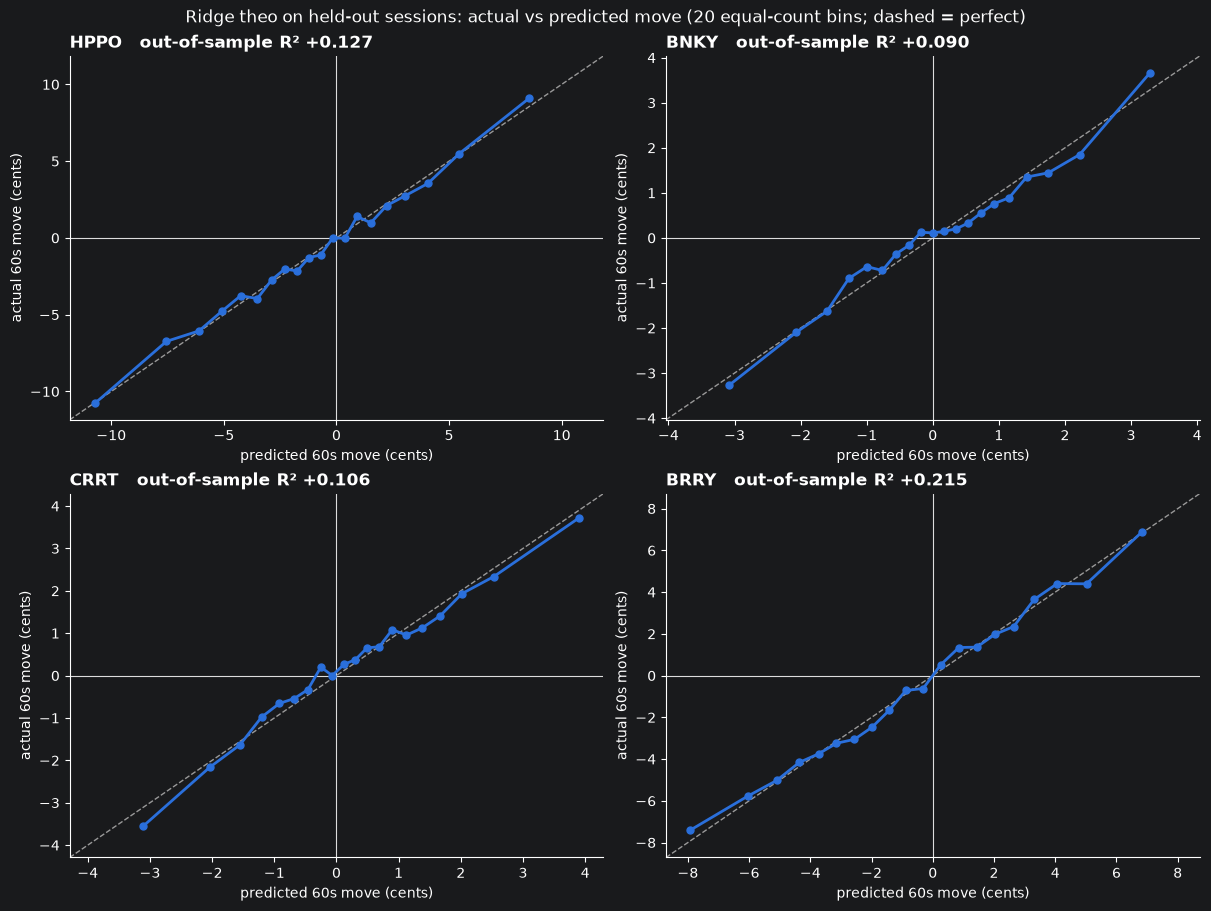

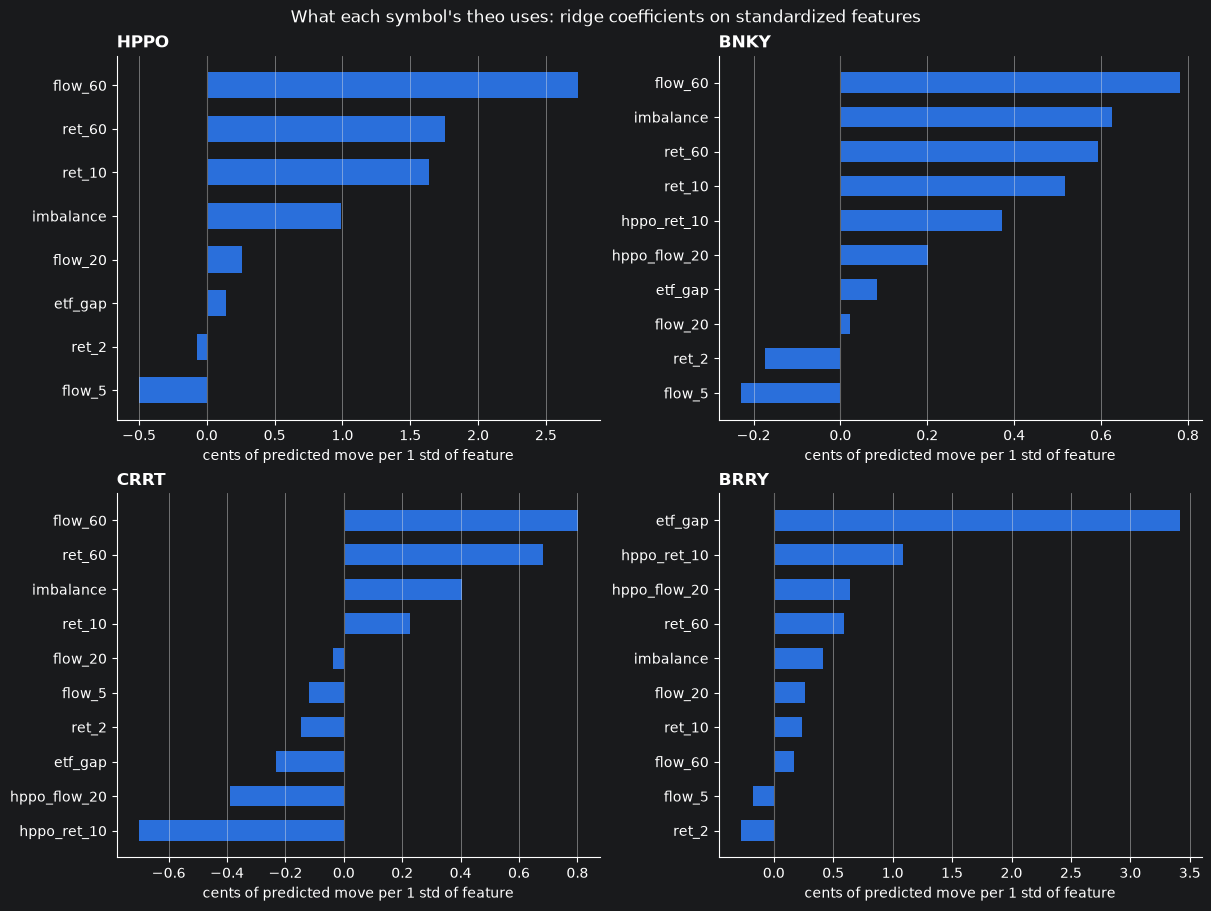

In [9]:
def plot_calibration(results, n_bins=20):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
    for ax, sym in zip(axes.flat, SYMBOLS):
        r = results[sym]
        d = pd.DataFrame({"pred": r["oof"], "real": r["y"]})
        d["bin"] = pd.qcut(d["pred"], n_bins, labels=False, duplicates="drop")
        b = d.groupby("bin").mean()
        lim = max(b.abs().max().max(), 1) * 1.1
        ax.plot([-lim, lim], [-lim, lim], color="#999999", linewidth=1, linestyle="--")
        ax.axhline(0, color="#dddddd", linewidth=0.8)
        ax.axvline(0, color="#dddddd", linewidth=0.8)
        ax.plot(b["pred"], b["real"], color="#2a6fdb", linewidth=2, marker="o", markersize=5)
        ax.set_title(f"{sym}   out-of-sample R² {r['fold_r2'].mean():+.3f}", loc="left", fontweight="bold")
        ax.set_xlabel("predicted 60s move (cents)")
        ax.set_ylabel("actual 60s move (cents)")
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Ridge theo on held-out sessions: actual vs predicted move (20 equal-count bins; dashed = perfect)")
    return fig

def plot_coefficients(results):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
    for ax, sym in zip(axes.flat, SYMBOLS):
        coef = pd.Series(results[sym]["model"][-1].coef_, index=results[sym]["X"].columns).sort_values()
        ax.barh(coef.index, coef.values, color="#2a6fdb", height=0.6)
        ax.axvline(0, color="#666666", linewidth=0.8)
        ax.set_title(sym, loc="left", fontweight="bold")
        ax.set_xlabel("cents of predicted move per 1 std of feature")
        ax.grid(axis="x", color="#e5e5e5", linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("What each symbol's theo uses: ridge coefficients on standardized features")
    return fig

plot_calibration(results);
plot_coefficients(results);


In [10]:
def coefficients(results):
    return pd.DataFrame({s: pd.Series(r["model"][-1].coef_, index=r["X"].columns) for s, r in results.items()})

results_240 = {sym: evaluate(sym, horizon=240) for sym in SYMBOLS}
(pd.concat({"60s": coefficients(results), "120s": coefficients(results_240)}, axis=1)
   .swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)[SYMBOLS].round(2))


HPPO        BNKY        CRRT        BRRY      
               60s  120s   60s  120s   60s  120s   60s  120s
etf_gap       0.14 -0.02  0.08  0.05 -0.23 -0.54  3.42  4.29
flow_20       0.26  0.64  0.02  0.15 -0.04  0.10  0.26  0.36
flow_5       -0.50 -0.44 -0.23 -0.20 -0.12 -0.05 -0.17 -0.08
flow_60       2.74  3.34  0.78  1.05  0.80  1.22  0.17  0.62
hppo_flow_20   NaN   NaN  0.20  0.36 -0.39 -0.62  0.64  1.12
hppo_ret_10    NaN   NaN  0.37  0.52 -0.70 -0.82  1.09  1.13
imbalance     0.99  1.16  0.63  0.70  0.40  0.41  0.41  0.39
ret_10        1.64  1.72  0.52  0.47  0.23  0.23  0.24  0.18
ret_2        -0.07  0.14 -0.17 -0.07 -0.15 -0.10 -0.28 -0.19
ret_60        1.75  1.61  0.59  0.45  0.68  0.38  0.59  0.27

In [11]:
def export_theo(results, path="strategies/theo_model.json"):
    """Write each symbol's ridge model in raw units for strategies/theo_mm.py."""
    out = {"horizon": HORIZON, "symbols": {}}
    for sym, r in results.items():
        scaler, ridge = r["model"][0], r["model"][-1]
        w = ridge.coef_ / scaler.scale_                      # cents of predicted move per unit of feature
        out["symbols"][sym] = {
            "features": list(r["X"].columns),
            "weights": [float(v) for v in w],
            "intercept": float(-(w * scaler.mean_).sum()),   # centred features, no drift term
            "clip_lo": [float(v) for v in r["X"].min()],     # X was clipped at 1%/99%: these are the bounds
            "clip_hi": [float(v) for v in r["X"].max()],
        }
    Path(path).write_text(json.dumps(out, indent=2))
    print("wrote", path)

export_theo(results)

wrote strategies/theo_model.json


In [14]:
def export_theo(results, path="strategies/theo_model.json"):
    """Write each symbol's ridge model in raw units for strategies/theo_mm.py."""
    out = {"horizon": HORIZON, "trained_on": TRAIN_SESSIONS, "symbols": {}}
    for sym, r in results.items():
        scaler, ridge = r["model"][0], r["model"][-1]
        w = ridge.coef_ / scaler.scale_                      # cents of predicted move per unit of feature
        out["symbols"][sym] = {
            "features": list(r["X"].columns),
            "weights": [float(v) for v in w],
            "intercept": float(-(w * scaler.mean_).sum()),   # centred features, no drift term
            "clip_lo": [float(v) for v in r["X"].min()],     # X was clipped at 1%/99%: these are the bounds
            "clip_hi": [float(v) for v in r["X"].max()],
        }
    Path(path).write_text(json.dumps(out, indent=2))
    print(f"wrote {path} (trained on {len(TRAIN_SESSIONS)} sessions)")

export_theo(results)


wrote strategies/theo_model.json (trained on 18 sessions)


In [15]:
import dataclasses, logging, sys
sys.path.insert(0, "strategies")
from theo_mm import TheoMM
from pqt_client.backtest_v2 import load_session
from pqt_client.v2 import backtest_strategy

logging.getLogger("pqt").setLevel(logging.WARNING)   # hide the per-minute lines

def variant(**defaults):
    """TheoMM with some panel defaults changed, e.g. variant(skew=8, take_HPPO=50)."""
    params = tuple(dataclasses.replace(p, default=defaults.get(p.name, p.default)) for p in TheoMM.MODEL_PARAMS)
    return type("Variant", (TheoMM,), {"MODEL_PARAMS": params})

def run_holdout(**defaults):
    rows = {}
    for name in HOLDOUT:
        strat = variant(**defaults)()
        backtest_strategy(load_session("data", name), strat)
        rows[name] = {s: v / 100 for s, v in strat.markouts().items()}
    table = pd.DataFrame(rows).T
    table["total"] = table.sum(axis=1)
    table.loc["sum"] = table.sum()
    return table.round(0)

run_holdout()                  # baseline; then try e.g. run_holdout(skew=8) or run_holdout(take_HPPO=50)


,HPPO,BNKY,CRRT,BRRY,total
s19,-11.0,471.0,1209.0,1495.0,3164.0
s20,380.0,1103.0,1056.0,1555.0,4095.0
s21,621.0,836.0,889.0,1256.0,3602.0
s22,389.0,608.0,1120.0,1702.0,3818.0
s23,402.0,653.0,2001.0,1589.0,4644.0
s24,489.0,926.0,1309.0,1853.0,4577.0
sum,2269.0,4597.0,7583.0,9450.0,23899.0


In [19]:
run_holdout(take_HPPO=50)

,HPPO,BNKY,CRRT,BRRY,total
s19,558.0,489.0,1232.0,1505.0,3783.0
s20,409.0,1087.0,1085.0,1552.0,4132.0
s21,497.0,850.0,975.0,1316.0,3639.0
s22,416.0,661.0,1159.0,1736.0,3972.0
s23,528.0,666.0,2060.0,1642.0,4896.0
s24,779.0,913.0,1338.0,1839.0,4869.0
sum,3188.0,4666.0,7849.0,9589.0,25291.0


In [17]:
run_holdout(skew = 8)

,HPPO,BNKY,CRRT,BRRY,total
s19,101.0,467.0,1177.0,1564.0,3310.0
s20,288.0,1148.0,1123.0,1736.0,4294.0
s21,638.0,620.0,953.0,1278.0,3488.0
s22,344.0,613.0,1118.0,1919.0,3994.0
s23,361.0,594.0,1922.0,1824.0,4701.0
s24,458.0,805.0,1288.0,1984.0,4536.0
sum,2191.0,4248.0,7580.0,10305.0,24323.0


In [20]:
run_holdout(take_HPPO=50, skew=8)

,HPPO,BNKY,CRRT,BRRY,total
s19,480.0,472.0,1177.0,1564.0,3693.0
s20,436.0,1175.0,1125.0,1730.0,4466.0
s21,597.0,620.0,954.0,1283.0,3454.0
s22,380.0,615.0,1118.0,1944.0,4057.0
s23,466.0,594.0,1906.0,1824.0,4790.0
s24,622.0,805.0,1288.0,1984.0,4700.0
sum,2982.0,4280.0,7568.0,10329.0,25160.0
